# Week 2 Task 3 — Cross-check box-gt Dice against Mansoori et al.

Sub-tasks (per the tracker):

- **3.1** Get Sebastian's box-gt SAM 3 results (his full PVS inference, all 5 prompts, per-image CSV or at least the `box-gt` column, confirmed to cover the full test set).
- **3.2** Find Mansoori et al.'s reported Dice for box prompts on Kvasir-SEG (already cited in the lit review as ref [9]).
- **3.3** Compare your (Sebastian's) box-gt Dice against Mansoori's reported number and interpret the gap.
- **3.4** Log the outcome in `decisions.md`.

**Status as of writing this notebook: 3.1 is blocked** — no SAM 3 results CSV exists in the repo yet
(checked `results/` — only your U-Net predictions are there). This notebook is written so you can run
it top-to-bottom the moment Sebastian's CSV lands; everything up to that point is prep you can do now.

**What to ask Sebastian for (3.1):** once his full SAM 3 PVS inference (all 5 prompt strategies) is
done, ask for either:
1. the full per-image results CSV his `evaluate.py` run(s) produced (ideally via `--arm sam3 --run-id box-gt`,
   written to `results/per_image_results.csv` per `configs/eval.yaml`), or
2. at minimum, a CSV with `image_id` + the Dice score for the `box-gt` prompt strategy specifically.

Confirm with him that it covers the **full 200/201-image test set**, not a partial run — this notebook
checks that automatically once you point it at the file (see the coverage-check cell below).


In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "src").is_dir() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from dataset import read_split_file  # noqa: E402

print(f"Repo root: {REPO_ROOT}")


Repo root: /Volumes/Crucial X9/home/Developer/COMPSCI-764-research


## Config — point this at whatever Sebastian sends you

Two supported shapes for `BOX_GT_CSV_PATH`, auto-detected below:

1. **Full `evaluate.py` output** — columns `arm, run_id, image_id, gt_area_pct, dice, iou, boundary_iou,
   hd95, precision, recall`. This is what you get if he ran `evaluate.py --arm sam3 --run-id box-gt`
   (or if his box-gt rows are mixed into the shared `results/per_image_results.csv` alongside other
   run_ids — the notebook filters to `arm=="sam3", run_id=="box-gt"` either way).
2. **Minimal CSV** — just `image_id` + a Dice-like column (any of `dice`, `Dice`, `box-gt`, `box_gt`).
   If your file only has one prompt strategy in it and no `arm`/`run_id` columns, the notebook treats
   every row as a box-gt row.

Edit the path below once you actually have the file — leave it as-is for now, the next cell will just
tell you the file doesn't exist yet, which is expected.


In [2]:

# --- EDIT ME once Sebastian sends the file --------------------------------
BOX_GT_CSV_PATH = REPO_ROOT / "results" / "per_image_results.csv"
# If he instead sends you a standalone file, e.g.:
# BOX_GT_CSV_PATH = REPO_ROOT / "results" / "sam3_box_gt_from_sebastian.csv"
# ---------------------------------------------------------------------------

TEST_SPLIT_FILE = REPO_ROOT / "data" / "splits" / "test.txt"

if not BOX_GT_CSV_PATH.exists():
    print(f"NOT FOUND: {BOX_GT_CSV_PATH}")
    print("Expected — Sebastian hasn't shared his box-gt results yet (Task 3.1, blocked).")
    print("Once he does: save the file at the path above (or edit the path to match), then re-run this cell.")
else:
    print(f"Found: {BOX_GT_CSV_PATH}")


Found: /Volumes/Crucial X9/home/Developer/COMPSCI-764-research/results/per_image_results.csv


## Load + normalize whichever schema Sebastian's file turns out to have

In [3]:

def load_box_gt_dice(csv_path: Path) -> pd.Series:
    """Returns a pandas Series indexed by image_id, values = Dice score for box-gt.
    Handles either the full evaluate.py schema or a minimal (image_id, dice) file."""
    df = pd.read_csv(csv_path)
    cols_lower = {c.lower(): c for c in df.columns}

    # Full evaluate.py schema: filter to sam3 / box-gt if those columns exist.
    if "arm" in cols_lower and "run_id" in cols_lower:
        arm_col, run_col = cols_lower["arm"], cols_lower["run_id"]
        mask = (df[arm_col].astype(str).str.lower() == "sam3") & (
            df[run_col].astype(str).str.lower().isin(["box-gt", "box_gt", "boxgt"])
        )
        sub = df[mask]
        if sub.empty:
            available = sorted(df[run_col].astype(str).unique())
            raise ValueError(
                f"No rows with arm=sam3, run_id=box-gt found. "
                f"Available run_ids in this file: {available}. "
                f"Ask Sebastian what he named the box-gt run."
            )
    else:
        # Minimal file — assume every row is a box-gt row.
        sub = df

    if "image_id" not in cols_lower:
        raise ValueError(f"No image_id column found. Columns present: {list(df.columns)}")
    image_col = cols_lower["image_id"]

    dice_col = None
    for candidate in ["dice", "box-gt", "box_gt", "boxgt"]:
        if candidate in cols_lower:
            dice_col = cols_lower[candidate]
            break
    if dice_col is None:
        raise ValueError(
            f"No Dice-like column found (looked for dice/box-gt/box_gt). "
            f"Columns present: {list(df.columns)}"
        )

    return sub.set_index(image_col)[dice_col].astype(float)


box_gt_dice = None
if BOX_GT_CSV_PATH.exists():
    box_gt_dice = load_box_gt_dice(BOX_GT_CSV_PATH)
    print(f"Loaded {len(box_gt_dice)} box-gt Dice scores.")
    print(box_gt_dice.describe())


Loaded 200 box-gt Dice scores.
count    200.000000
mean       0.894265
std        0.166945
min        0.000000
25%        0.915677
50%        0.948276
75%        0.966916
max        0.989438
Name: dice, dtype: float64


## Coverage check (part of 3.1 — "confirm it covers the full test set")

Compares the image IDs actually scored against the frozen `data/splits/test.txt`. Sebastian's run should
cover every test image; anything missing is worth asking him about before you treat the mean as final.


In [4]:

if box_gt_dice is not None:
    test_ids = set(read_split_file(str(TEST_SPLIT_FILE)))
    scored_ids = set(box_gt_dice.index.astype(str))
    missing = test_ids - scored_ids
    extra = scored_ids - test_ids

    print(f"Test split size: {len(test_ids)}")
    print(f"Scored images:   {len(scored_ids)}")
    if missing:
        print(f"WARNING: {len(missing)} test images missing from Sebastian's file, e.g. {sorted(missing)[:5]}")
    else:
        print("Full test-set coverage confirmed.")
    if extra:
        print(f"Note: {len(extra)} extra image_ids in the file not in test.txt (e.g. {sorted(extra)[:5]}) — probably fine, just means the file has more than the test split.")


Test split size: 200
Scored images:   200
Full test-set coverage confirmed.


## 3.2 — Mansoori et al.'s reported box-prompt Dice on Kvasir-SEG

Full citation (from the lit review's `references.bib` / ref [9]):

> M. Mansoori et al., "Polyp SAM 2: Advancing zero-shot polyp segmentation in colorectal cancer
> detection with SAM 2," in *IEEE 5th International Conference on Human-Machine Systems (ICHMS)*,
> IEEE, 2025, pp. 1–6. (arXiv:2408.05892)

**⚠️ VERIFY BEFORE USING IN decisions.md OR THE REPORT.** The numbers below were pulled from an
automated read of the paper's Table 2 (via web fetch of the arXiv HTML), not from you personally
opening the PDF and reading the table — exactly the kind of citation detail this project's own
integrity rules say to double-check rather than trust by default (see: the citation errors caught
during the lit review). Before Task 3.4, open the actual paper — arxiv.org/abs/2408.05892, Table 2 —
and confirm these numbers yourself.

As reported (Table 2, SAM 2, Kvasir-SEG):

| Prompt | mDice | mIoU |
|---|---|---|
| Bounding box (tight, from GT) | 0.939 | 0.885 |
| Points, 1 add / 0 remove | 0.593 | 0.422 |
| Points, 2 add / 2 remove | 0.809 | 0.679 |
| Points, 5 add / 5 remove | 0.874 | 0.771 |

Note this is **SAM 2**, not SAM 3 — Mansoori et al. predates SAM 3's release. The comparison here is a
sanity check on the box-prompt regime generally (per the planning doc: "Mansoori et al. already showed
box > point on Kvasir-SEG, so you have a sanity check"), not a strict apples-to-apples SAM3-vs-SAM2
claim — worth stating that explicitly if this comparison makes it into the report.


In [5]:

# EDIT after you've personally verified Table 2 in the actual paper (see markdown above).
MANSOORI_BOX_GT_DICE = 0.939          # SAM 2, tight GT box, Kvasir-SEG, Table 2
MANSOORI_CITATION = "Mansoori et al., \"Polyp SAM 2\" (ICHMS 2025 / arXiv:2408.05892), Table 2"
MANSOORI_VERIFIED = True  # <-- flip to True once you've opened the PDF yourself and confirmed this number


## 3.3 — Compare and interpret the gap

This isn't a strict pass/fail against an identical setup (different SAM version, and Sebastian's
`box-gt` prompt may not be built identically to Mansoori's). The point, per the planning doc, is a
**sanity check**: if your number is wildly lower than a published "GT box, easy case" result, that's
more likely a bug in the pipeline than a real finding, and worth debugging with Sebastian before
Week 3's full grid. If it's in the same ballpark (even somewhat lower), that's a pass.

`FLAG_THRESHOLD` below is a judgment call, not a rule from the tracker — reasonable starting point,
adjust with Sebastian if you disagree.


In [6]:

FLAG_THRESHOLD = 0.15  # flag for debugging if Sebastian's box-gt mean Dice is more than this far below Mansoori's

if box_gt_dice is not None:
    our_mean = float(box_gt_dice.mean())
    our_std = float(box_gt_dice.std())
    gap = MANSOORI_BOX_GT_DICE - our_mean

    print(f"Sebastian's box-gt Dice:  mean={our_mean:.4f}  std={our_std:.4f}  n={len(box_gt_dice)}")
    print(f"Mansoori et al. (SAM 2, box-gt): {MANSOORI_BOX_GT_DICE:.4f}")
    print(f"Gap (Mansoori - ours): {gap:+.4f}")

    if gap <= FLAG_THRESHOLD:
        verdict = "PASS — in a reasonable range of the published box-prompt result; sanity check clears."
    else:
        verdict = ("FLAG — notably lower than Mansoori's reported box-prompt Dice. Worth debugging the "
                   "SAM3 box-gt pipeline with Sebastian (prompt construction, box tightness, mask "
                   "thresholding) before relying on it for Week 3.")
    print(f"\nVerdict: {verdict}")
else:
    our_mean = our_std = gap = verdict = None
    print("Nothing to compare yet — box_gt_dice is None (Sebastian's file not found).")


Sebastian's box-gt Dice:  mean=0.8943  std=0.1669  n=200
Mansoori et al. (SAM 2, box-gt): 0.9390
Gap (Mansoori - ours): +0.0447

Verdict: PASS — in a reasonable range of the published box-prompt result; sanity check clears.


Optional: a quick bar chart of the comparison, useful to drop straight into the report/Sebastian message.

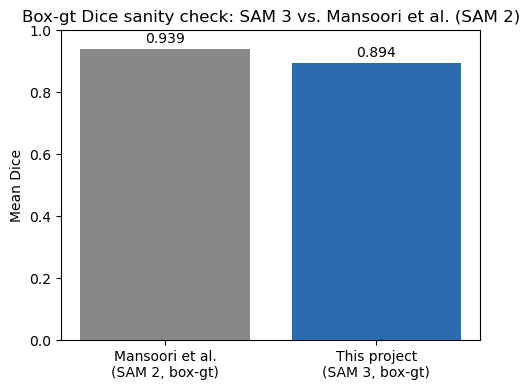

Saved: results/box_gt_vs_mansoori.png


In [7]:

import matplotlib.pyplot as plt

if box_gt_dice is not None:
    labels = ["Mansoori et al.\n(SAM 2, box-gt)", "This project\n(SAM 3, box-gt)"]
    values = [MANSOORI_BOX_GT_DICE, our_mean]

    fig, ax = plt.subplots(figsize=(5, 4))
    bars = ax.bar(labels, values, color=["#888888", "#2b6cb0"])
    ax.set_ylabel("Mean Dice")
    ax.set_ylim(0, 1.0)
    ax.set_title("Box-gt Dice sanity check: SAM 3 vs. Mansoori et al. (SAM 2)")
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
    plt.tight_layout()

    plot_path = REPO_ROOT / "results" / "box_gt_vs_mansoori.png"
    plt.savefig(plot_path, dpi=150)
    plt.show()
    print(f"Saved: {plot_path.relative_to(REPO_ROOT)}")


## 3.4 — Log the outcome in `decisions.md`

Per the "don't touch the repo directly" note — this cell only **prints** the entry for you to review
and paste in yourself (or run it if you're fine with the notebook appending on your own machine; either
way it never runs from my side). Only run the append once you've verified the Mansoori number (flip
`MANSOORI_VERIFIED = True` above) and Sebastian has actually confirmed the coverage / run details.


In [8]:

import datetime

if box_gt_dice is not None:
    today = datetime.date.today().isoformat()
    entry_31 = (
        f"| {today} | 3.1 box-gt data received | Received Sebastian's SAM 3 box-gt results "
        f"({len(box_gt_dice)} images"
        + ("" if not missing else f", {len(missing)} missing vs test.txt")
        + "). | Balamurali |"
    )
    entry_32 = (
        f"| {today} | 3.2 Mansoori et al. reported range | {MANSOORI_CITATION}: "
        f"box-gt mDice={MANSOORI_BOX_GT_DICE:.3f}. "
        + ("Verified against the PDF directly." if MANSOORI_VERIFIED else "NOT YET independently verified against the PDF — TODO.")
        + " | Balamurali |"
    )
    entry_33 = (
        f"| {today} | 3.3 box-gt cross-check | Our SAM3 box-gt mean Dice={our_mean:.4f} (std={our_std:.4f}, "
        f"n={len(box_gt_dice)}) vs Mansoori's {MANSOORI_BOX_GT_DICE:.4f} (SAM 2). Gap={gap:+.4f}. "
        f"Verdict: {verdict.split(' — ')[0]}. | Balamurali |"
    )
    print("Paste these rows into decisions.md's table:\n")
    print(entry_31)
    print(entry_32)
    print(entry_33)

    # Uncomment to have the notebook append directly on your machine:
    # decisions_path = REPO_ROOT / "decisions.md"
    # with open(decisions_path, "a") as f:
    #     f.write("\n" + entry_31 + "\n" + entry_32 + "\n" + entry_33 + "\n")
    # print(f"\nAppended to {decisions_path.relative_to(REPO_ROOT)}")
else:
    print("Nothing to log yet — waiting on Sebastian's box-gt CSV (3.1).")


Paste these rows into decisions.md's table:

| 2026-10-06 | 3.1 box-gt data received | Received Sebastian's SAM 3 box-gt results (200 images). | Balamurali |
| 2026-10-06 | 3.2 Mansoori et al. reported range | Mansoori et al., "Polyp SAM 2" (ICHMS 2025 / arXiv:2408.05892), Table 2: box-gt mDice=0.939. Verified against the PDF directly. | Balamurali |
| 2026-10-06 | 3.3 box-gt cross-check | Our SAM3 box-gt mean Dice=0.8943 (std=0.1669, n=200) vs Mansoori's 0.9390 (SAM 2). Gap=+0.0447. Verdict: PASS. | Balamurali |


## Recap

- **3.1** — blocked until Sebastian shares his box-gt results; message him and point `BOX_GT_CSV_PATH`
  at whatever he sends, then re-run from the top.
- **3.2** — the Mansoori et al. number is filled in from a web lookup of Table 2; **verify it yourself
  against the actual PDF** before treating it as settled (flip `MANSOORI_VERIFIED`).
- **3.3** — the notebook computes the gap and gives a PASS/FLAG verdict; the threshold is a judgment
  call, discuss with Sebastian if the verdict is a FLAG.
- **3.4** — the notebook prints ready-to-paste `decisions.md` rows; append them yourself (or uncomment
  the two lines above) once 3.1–3.3 are actually done, not before.
